In [48]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import QFT, UnitaryGate

from math import gcd
from fractions import Fraction

import numpy as np

Example for N = 15, a = 2

In [49]:
# Modular multiplication: construct the operator \(U|x\rangle=|2x\bmod15\rangle\).

N = 15
a = 2

# Check the condition
assert gcd(a, N) == 1, "a and N must be coprime."

# Number of qubits needed to represent N-1
n_target = (N - 1).bit_length()  # N - 1 = 14 and 2^4 = 16 and 16 > 14, so we need 4 qubits
dimension = 2 ** n_target  # dimension = 16

# Permutation matrix for modular multiplication
# Matrix for which you are going to estimate the phase
U = np.zeros((dimension, dimension), dtype=complex)
for x in range(dimension):
    y = (a * x) % N if x < N else x  # For x >= N, we leave it unchanged
    U[y, x] = 1

In [50]:
# Quantum order finding: prepare the target register in \(|1\rangle\), 
# apply controlled powers of \(U\), then an inverse QFT.


n_estimation = n_target  # Four estimation qubits suffice for this example.
target_qubits = list(range(n_estimation, n_estimation + n_target))

shor = QuantumCircuit(n_target + n_target, n_target)

for i in range(n_target):
    shor.h(i)  # Prepare |+> in the control register

shor.x(target_qubits[0])  # Prepare |1> in the target register

# Apply controlled-U operations
for i in range(n_target):
    U_power= np.linalg.matrix_power(U, 2 ** i)  # NumpPy matrix
    # convert to Qiskit UnitaryGate
    controlled_U = UnitaryGate(U_power, label=f'U^{2**i}').control()
    
    shor.append(controlled_U, [i, *target_qubits])

# Inverse QFT
shor.append(QFT(n_target, inverse=True).to_gate(), range(n_target))

C:\Users\jaroslav.pavlicko\AppData\Local\Temp\ipykernel_31084\1090146565.py:24: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  shor.append(QFT(n_target, inverse=True).to_gate(), range(n_target))


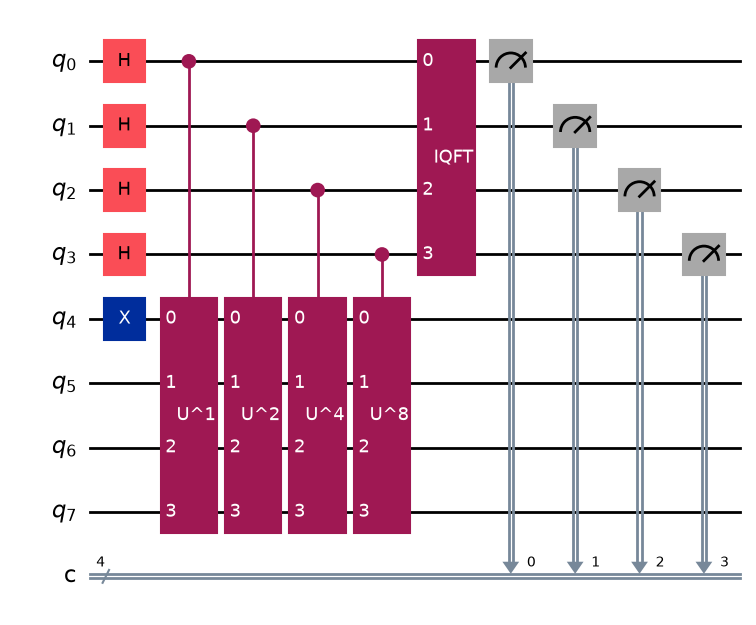

In [51]:
# Measurement: measure the phase register 
# and interpret the results as approximations to \(s/r\).

shor.measure(range(n_estimation), range(n_estimation))
shor.draw(output='mpl')

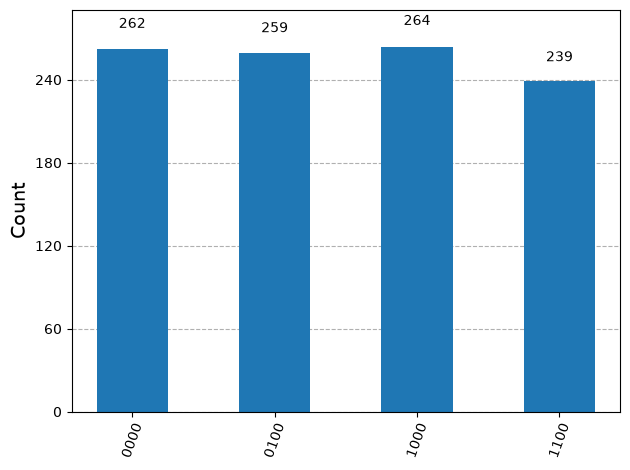

In [52]:
simulator = AerSimulator()
compiled_shor = transpile(shor, simulator)

result = simulator.run(compiled_shor, shots=1024).result()
counts = result.get_counts()
plot_histogram(counts)

In [ ]:
# Classical processing: recover a candidate order \(r\), 
# validate it, and calculate the factors using GCDs.

factors = None

# Try the most frequent measurement outcome
for bitstring, frequency in sorted(
    counts.items(), key=lambda item: item[1], reverse=True
):
    y = int(bitstring, 2)

    # zero phase gives no information about order
    if y == 0:
        continue 

    # Approximate the measured phase by a fraction with denominator <= N.
    phase = Fraction(y, 2**n_estimation).limit_denominator(N)
    r = phase.denominator

    print(f"{bitstring}: phase ≈ {phase}, candidate order = {r}")

    # Validate the candidate order
    # for odd orders you don't get integer r/2
    if r % 2 != 0:
        print("candidate is odd")
        continue

    x = pow(a, r//2, N)

    # Skip if candidate is either 1 or N - 1
    # Provides only trivial factors
    if x in (1, N - 1):
        print("candidate is trivial")
        continue

    p = gcd(x - 1, N)
    q = gcd(x + 1, N)

    if 1 < p < N and 1 < q < N and p * q == N:
        factors = (p, q)
        print(f"Factors found: {p} × {q} = {N}")
        # break

if factors is None:
    print("No factors found; repeat order finding or try another base a.")

1000: phase ≈ 1/2, candidate order = 2
0100: phase ≈ 1/4, candidate order = 4
Factors found: 3 × 5 = 15
1100: phase ≈ 3/4, candidate order = 4
Factors found: 3 × 5 = 15
